# Day 1 – Customer Churn Prediction & Retention Analysis

## Objective
The objective of Day 1 was to understand the customer churn dataset and perform initial data analysis.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [9]:
df = pd.read_csv("customer_churn_dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [10]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [11]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 7043
Number of Columns: 21


In [12]:
print("Dataset Columns:")
for column in df.columns:
    print(column)

Dataset Columns:
customerID
gender
SeniorCitizen
Partner
Dependents
tenure
PhoneService
MultipleLines
InternetService
OnlineSecurity
OnlineBackup
DeviceProtection
TechSupport
StreamingTV
StreamingMovies
Contract
PaperlessBilling
PaymentMethod
MonthlyCharges
TotalCharges
Churn


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [14]:
df.describe(include="all")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [15]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [16]:
print("Number of Duplicate Rows:", df.duplicated().sum())

Number of Duplicate Rows: 0


In [17]:
print("Customer Churn Distribution:")
print(df["Churn"].value_counts())

Customer Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [18]:
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print("Customer Churn Percentage:")
print(churn_percentage)

Customer Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


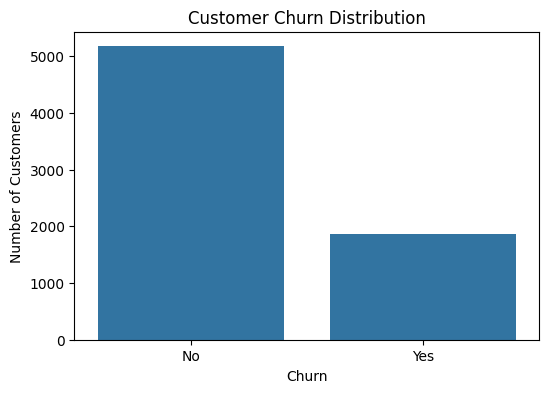

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [21]:
print("Churn Column Data Types:")
print(df["Churn"].dtype)

print("\nChurn Values:")
print(df["Churn"].unique())

Churn Column Data Types:
object

Churn Values:
['No' 'Yes']


In [22]:
print("Gender Distribution:")
print(df["gender"].value_counts())

Gender Distribution:
gender
Male      3555
Female    3488
Name: count, dtype: int64


In [23]:
print("Contract Type Distribution:")
print(df["Contract"].value_counts())

Contract Type Distribution:
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64


In [24]:
print("Payment Method Distribution:")
print(df["PaymentMethod"].value_counts())

Payment Method Distribution:
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64


In [25]:
for column in df.columns:
    print("\nColumn:", column)
    print("Unique Values:", df[column].nunique())


Column: customerID
Unique Values: 7043

Column: gender
Unique Values: 2

Column: SeniorCitizen
Unique Values: 2

Column: Partner
Unique Values: 2

Column: Dependents
Unique Values: 2

Column: tenure
Unique Values: 73

Column: PhoneService
Unique Values: 2

Column: MultipleLines
Unique Values: 3

Column: InternetService
Unique Values: 3

Column: OnlineSecurity
Unique Values: 3

Column: OnlineBackup
Unique Values: 3

Column: DeviceProtection
Unique Values: 3

Column: TechSupport
Unique Values: 3

Column: StreamingTV
Unique Values: 3

Column: StreamingMovies
Unique Values: 3

Column: Contract
Unique Values: 3

Column: PaperlessBilling
Unique Values: 2

Column: PaymentMethod
Unique Values: 4

Column: MonthlyCharges
Unique Values: 1585

Column: TotalCharges
Unique Values: 6531

Column: Churn
Unique Values: 2


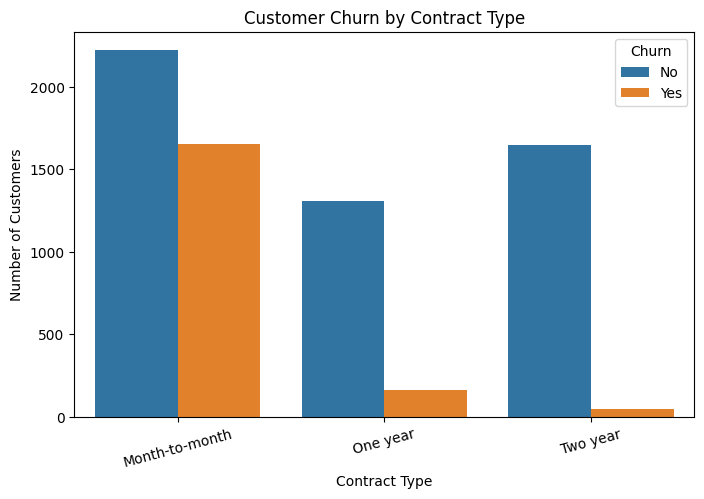

In [26]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.xticks(rotation=15)
plt.show()

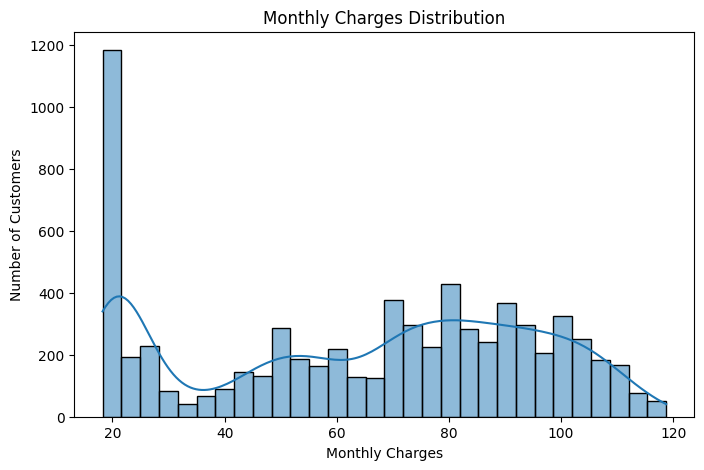

In [27]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="MonthlyCharges", bins=30, kde=True)

plt.title("Monthly Charges Distribution")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.show()

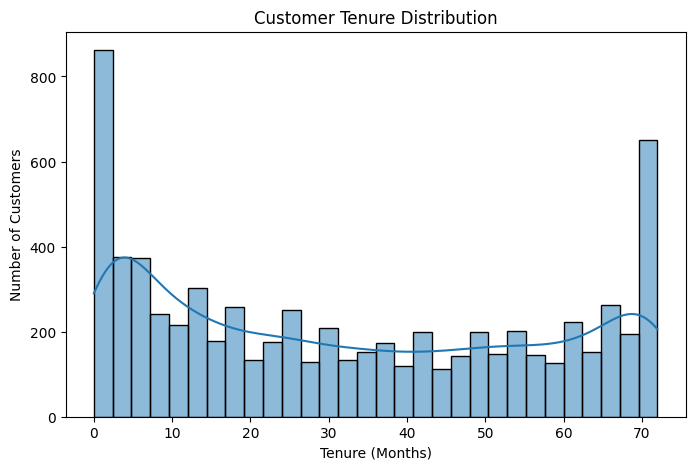

In [28]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="tenure", bins=30, kde=True)

plt.title("Customer Tenure Distribution")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

In [29]:
df.to_csv("customer_churn_day1.csv", index=False)

print("Day 1 dataset saved successfully!")

Day 1 dataset saved successfully!



## Tasks Completed
- Loaded the customer churn dataset using Pandas.
- Explored dataset dimensions, columns, and data types.
- Generated statistical summaries.
- Checked missing values and duplicate records.
- Analyzed customer churn distribution and percentages.
- Explored gender, contract type, and payment methods.
- Created visualizations for churn, monthly charges, and customer tenure.
- Saved the dataset for further analysis.

## Conclusion
Day 1 helped me understand the customer dataset, identify important features, and explore customer churn patterns through basic data analysis and visualization. This analysis provides a foundation for the next stages of customer churn prediction using machine learning.